In [1]:
import gym
import gym_mppt
from gym import envs
env = gym.make("mppt_shaded-v3")

num_obs = env.observation_space.shape[0]
print("Size of Observation Space ->  {}".format(num_obs))
print(env.observation_space)

print()

num_actions = env.action_space.shape[0]
print("Size of Action Space ->  {}".format(num_actions))
print(env.action_space)

Size of Observation Space ->  8
Box([  0.   0.   0. -inf -inf -inf -inf -inf], [212.  inf  inf  inf  inf  inf  inf  inf], (8,), float32)

Size of Action Space ->  1
Box([-5.], [5.], (1,), float32)


C:\Users\archi\anaconda3\envs\BTPtorch\lib\site-packages\gym\spaces\box.py:73: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(


[-0.9921875   1.         -0.9863281   0.19921875  0.3984375   0.01367188
  0.01367188  0.        ] {'Steps': 1, 'Voltage': 1.0, 'Current': 375.47209907487456, 'Power': 375.4721, 'NormPower': 0.006972924010551557, 'Temperature': 25, 'Irradiance': 1000, 'Shading': [10, 10, 10, 10, 10, 10]} -1.0
[-0.9824219   1.         -0.97265625  0.19921875 -0.00195312  0.01367188
  0.01367188  0.        ] {'Steps': 2, 'Voltage': 2.0, 'Current': 375.4713957248386, 'Power': 750.94279, 'NormPower': 0.01394582183587429, 'Temperature': 25, 'Irradiance': 1000, 'Shading': [10, 10, 10, 10, 10, 10]} -1.0
[-0.97265625  1.         -0.9589844   0.19921875 -0.00195312  0.01367188
  0.01367188  0.        ] {'Steps': 3, 'Voltage': 3.0, 'Current': 375.47065751549826, 'Power': 1126.41197, 'NormPower': 0.02091869161885978, 'Temperature': 25, 'Irradiance': 1000, 'Shading': [10, 10, 10, 10, 10, 10]} -1.0
[-0.9628906   1.         -0.9453125   0.19921875 -0.00195312  0.01367188
  0.01367188  0.        ] {'Steps': 4, 'Volta

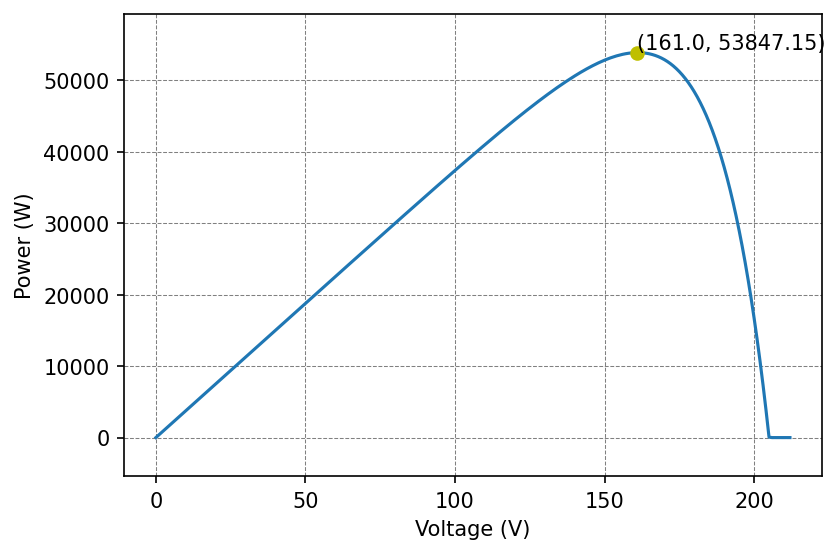

In [2]:
from scipy.signal import find_peaks

obs = env.reset()
obs = env.render([10, 10, 10, 10, 10, 10, 25, 1000])
powerlst = []
rewlst = []
voltlst = []

powerlst.append(0)
rewlst.append(0)
voltlst.append(0)

for i in range(212):
    obs, rewards, dones, info = env.step(1)
    print(obs, info, rewards)
    voltlst.append(info['Voltage'])
    powerlst.append(info['Power'])
    rewlst.append(rewards)
    
peaks, _ = find_peaks(powerlst, prominence=1)
print(peaks)

maxp = -1
for peak in peaks:
    if powerlst[peak] > powerlst[maxp]:
        maxp = peak

import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

plt.figure(figsize=(6, 4), dpi=150)
plt.grid(True, color = "grey", linewidth = "0.5", linestyle="--")
plt.xlabel('Voltage (V)')
plt.ylabel('Power (W)')
plt.text(voltlst[maxp], powerlst[maxp] + 500, '({}, {})'.format(str(round(voltlst[maxp], 2)), str(round(powerlst[maxp], 2))))
plt.margins(x=0.05, y=0.1)
plt.plot(voltlst, powerlst)
plt.plot(voltlst[maxp], powerlst[maxp], "oy")
# plt.plot(rewlst)

In [27]:
print(info['Temperature'])

67


In [28]:
info['Temperature'] != 263.76

True

In [29]:
round(voltlst[maxp], 2)

46.0

In [30]:
import pandas as pd

In [31]:
df = pd.DataFrame(data = [powerlst, rewlst]).T
df.rename(columns={0: 'Power', 1: 'Reward'}, inplace=True)

In [32]:
df

,Power,Reward
0,0.00000,0.00
1,157.70254,-1.00
2,315.34934,-1.00
3,472.93164,-1.00
4,630.43947,-0.42
...,...,...
208,0.00000,-1.00
209,0.00000,-1.00
210,0.00000,-1.00
211,0.00000,-1.00


<Axes: >

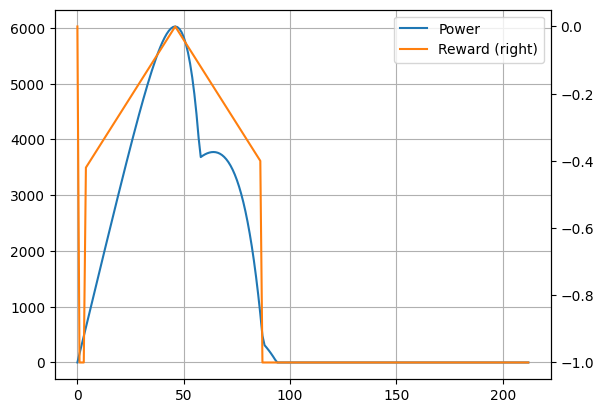

In [33]:
df.Power.plot(label="Power", legend=True, grid = True)
df.Reward.plot(secondary_y=True, label="Reward", legend=True)

In [ ]:
obs = env.reset()
obs = env.render([1, 10, 7, 10, 3, 10, 25, 1000])
A0 = []
A1 = []
A2 = []
A3 = []
A4 = []
A5 = []
A6 = []
A7 = []
for i in range(210):
    obs, rewards, dones, info = env.step(1)
    A0.append(obs[0])
    A1.append(obs[1])
    A2.append(obs[2])
    A3.append(obs[3])
    A4.append(obs[4])
    A5.append(obs[5])
    A6.append(obs[6])
    A7.append(obs[7])

In [ ]:
plt.plot(A0)

In [ ]:
plt.plot(A1)

In [ ]:
plt.plot(A2)

In [ ]:
plt.plot(A3)

In [ ]:
plt.plot(A4)

In [ ]:
plt.plot(A5)

In [ ]:
plt.plot(A6)

In [ ]:
plt.plot(A7)

In [10]:
pirrlst = []
for irr in [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]:
    obs = env.reset()
    obs = env.render([10, 10, 10, 10, 10, 10, 25, irr])
    powerlst = []
    rewlst = []
    voltlst = []

    powerlst.append(0)
    rewlst.append(0)
    voltlst.append(0)

    for i in range(210):
        obs, rewards, dones, info = env.step(1)
    #     print(obs, info)
        voltlst.append(info['Voltage'])
        powerlst.append(info['Power'])
        rewlst.append(rewards)

    peaks, _ = find_peaks(powerlst, prominence=1)
#     print(peaks)

    maxp = -1
    for peak in peaks:
        if powerlst[peak] > powerlst[maxp]:
            maxp = peak

    print(irr, powerlst[maxp])
    pirrlst.append(powerlst[maxp])

100 3881.39386
200 8655.55357
300 13775.11931
400 19119.96865
500 24632.69199
600 30280.24942
700 36038.82076
800 41894.3208
900 47833.04623
1000 53847.15213


In [11]:
pirrlst

[3881.39386,
 8655.55357,
 13775.11931,
 19119.96865,
 24632.69199,
 30280.24942,
 36038.82076,
 41894.3208,
 47833.04623,
 53847.15213]

In [14]:
for i in range(len(pirrlst) - 1):
    diff = pirrlst[i+1] - pirrlst[i]
    print(diff)

4774.15971
5119.56574
5344.849339999999
5512.7233400000005
5647.557430000001
5758.571340000002
5855.500039999999
5938.725429999999
6014.105900000002


In [ ]:
import matplotlib.pyplot as plt

In [ ]:
irr = 800.
temp = 25.
irrlst = [irr]
templst = [temp]

for i in range(2500):
    if i <= 500:
        irr = 800.
        temp += 0.01
    elif i <= 1000:
        irr = 1000.
        temp = 30.
    elif i <= 1500:
        irr = 600.
        temp -= 0.02
    elif i <= 2000:
        irr = 1000.
        temp = 20.
    elif i <= 2500:
        irr = 800.
        temp += 0.01
    irrlst.append(round(irr, 2))
    templst.append(round(temp, 2))

In [ ]:
plt.figure(figsize=(6, 4), dpi=150)
plt.grid(True, color = "grey", linewidth = "0.5", linestyle="--")
plt.xlabel('Time Step')
plt.ylabel('Irradiance (mW/cm^2)')
plt.plot(irrlst)

In [ ]:
len(templst)

In [ ]:
print(templst)

In [ ]:
plt.figure(figsize=(6, 4), dpi=150)
plt.grid(True, color = "grey", linewidth = "0.5", linestyle="--")
plt.xlabel('Time Step')
plt.ylabel('Temperature (°C)')
plt.plot(templst)

In [ ]:
import numpy as np
choice = np.load('choice.npy', allow_pickle = True)

In [ ]:
choice[2]

In [ ]:
np.save('templst.npy', templst)

In [ ]:
ls

In [ ]:
cd mppt-gym_v4/

In [ ]:
ls

In [ ]:
cd /home/archi/Code2/PPO-LSTM/mppt-gym_v4/

In [ ]:
ls

In [ ]:
cd gym_mppt/

In [ ]:
ls

In [ ]:
cd envs/

In [ ]:
import numpy as np
- np.abs(110 - 0) / 100

In [4]:
for i, m in enumerate([1]*9):
    print(i, m)

0 1
1 1
2 1
3 1
4 1
5 1
6 1
7 1
8 1


In [3]:
import random

In [9]:
random.randint(10, 40)

16

In [8]:
a = [1,2,3,4,5,6,7,8]

In [9]:
a[:6]

[1, 2, 3, 4, 5, 6]

In [11]:
a[6]

7

In [41]:
c = 1
a = {'b' : c}

In [42]:
a['b']

1

In [43]:
c = 2

In [44]:
a['b']

1

In [46]:
import numpy as np
a = 1
b = 2
state = np.array([a, b], dtype=np.float32)

In [47]:
state

array([1., 2.], dtype=float32)

In [48]:
a = 5
b = 7
print(state)

[1. 2.]
